In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [2]:
# Load MNIST dataset
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
# Normalize pixel values between 0 and 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [4]:
# Flatten the 28x28 images into 784 values
x_train = x_train.reshape((len(x_train), 784))
x_test = x_test.reshape((len(x_test), 784))

In [5]:
# Add random noise to the images
noise_factor = 0.2

In [6]:
x_train_noisy = x_train + noise_factor * np.random.normal(
    loc=0.0,
    scale=1.0,
    size=x_train.shape
)

x_test_noisy = x_test + noise_factor * np.random.normal(
    loc=0.0,
    scale=1.0,
    size=x_test.shape
)

In [7]:
# Keep pixel values between 0 and 1
x_train_noisy = np.clip(x_train_noisy, 0.0, 1.0)
x_test_noisy = np.clip(x_test_noisy, 0.0, 1.0)


In [8]:
# Define the input layer
input_img = Input(shape=(784,))

In [9]:
# Encoder
encoded = Dense(128, activation="relu")(input_img)
encoded = Dense(64, activation="relu")(encoded)
encoded = Dense(32, activation="relu")(encoded)


In [10]:
# Decoder
decoded = Dense(64, activation="relu")(encoded)
decoded = Dense(128, activation="relu")(decoded)
decoded = Dense(784, activation="sigmoid")(decoded)



In [11]:
# Create the autoencoder
autoencoder = Model(input_img, decoded)


In [12]:
# Compile the model
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)



In [13]:
# Display model architecture
autoencoder.summary()



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Train the autoencoder
history = autoencoder.fit(
    x_train_noisy,
    x_train,
    epochs=17,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_noisy, x_test)
)



Epoch 1/17
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 0.2593 - val_loss: 0.1756
Epoch 2/17
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.1586 - val_loss: 0.1453
Epoch 3/17
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1393 - val_loss: 0.1317
Epoch 4/17
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.1291 - val_loss: 0.1245
Epoch 5/17
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - loss: 0.1233 - val_loss: 0.1198
Epoch 6/17
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.1188 - val_loss: 0.1157
Epoch 7/17
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.1154 - val_loss: 0.1130
Epoch 8/17
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.1130 - val_loss: 0.1108
Epoch 9/17
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.1110 - val_loss: 0.1087
Epoch 10/17
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.1091 - val_loss: 0.1076
Epoch 11/17
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.1074 - val_loss: 0.1059
Epoch 12/17
235/235 ━━━━━━━━━━━━━━━━━━━━ 

In [15]:
# Reconstruct the noisy test images
decoded_images = autoencoder.predict(x_test_noisy)



313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


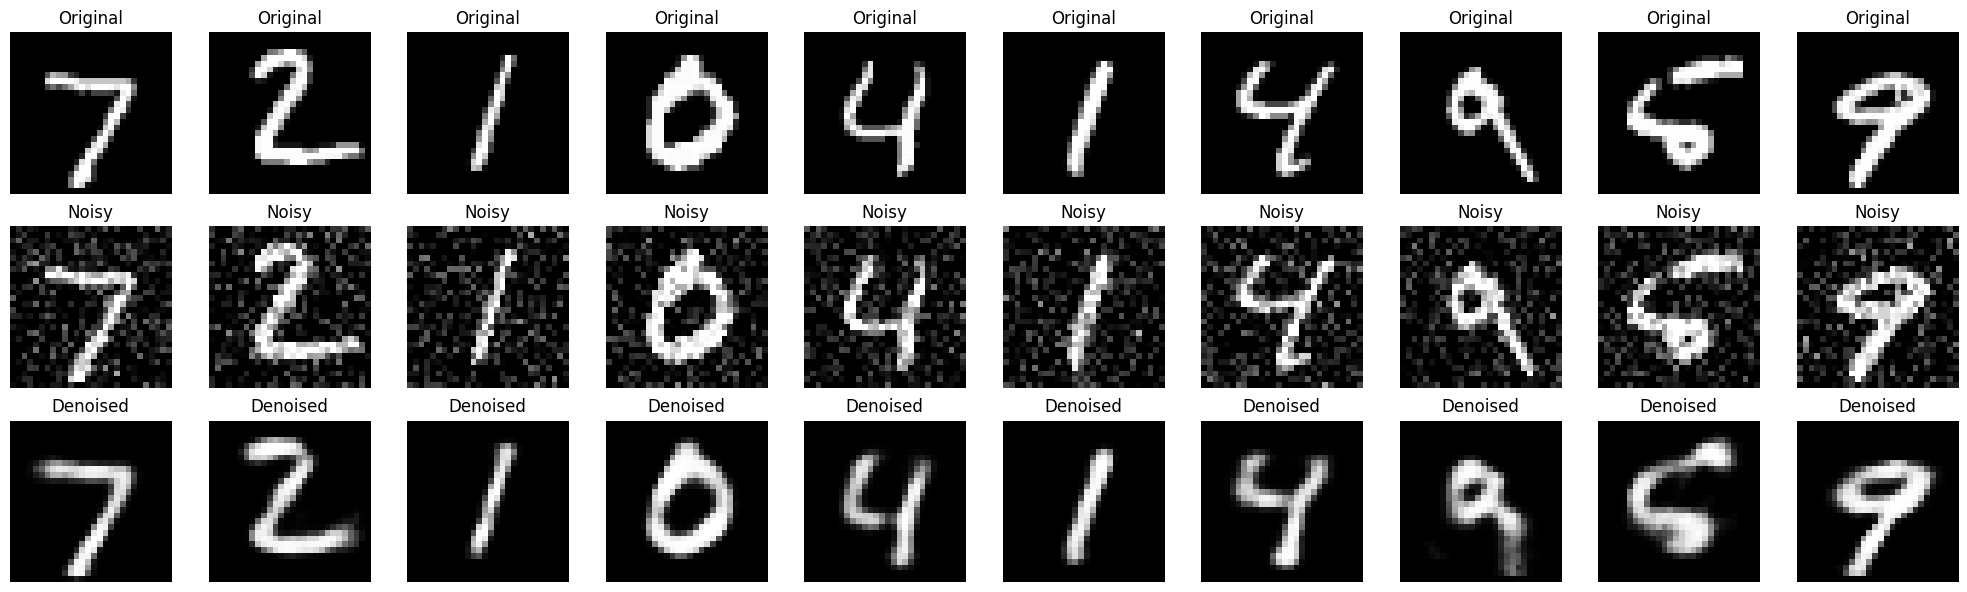

In [16]:
# Display original, noisy and denoised images
n = 10

plt.figure(figsize=(20, 6))

for i in range(n):

    # Original image
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Noisy image
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_noisy[i].reshape(28, 28), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

    # Denoised image
    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(decoded_images[i].reshape(28, 28), cmap="gray")
    plt.title("Denoised")
    plt.axis("off")

plt.tight_layout()
plt.show()


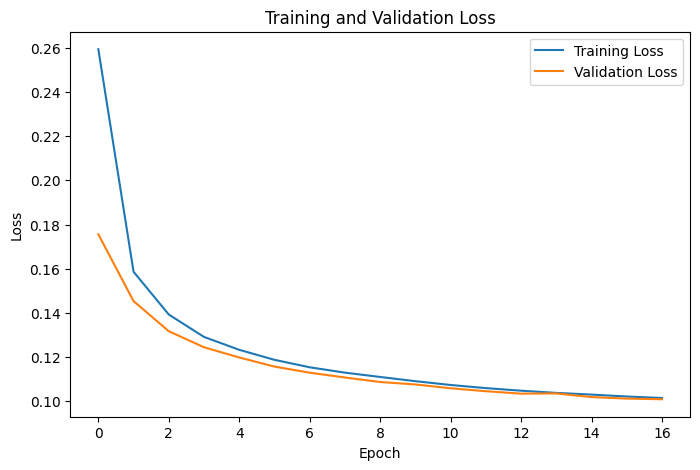

Test Reconstruction Loss: 0.10095266252756119


In [17]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

# Calculate reconstruction loss
test_loss = autoencoder.evaluate(
    x_test_noisy,
    x_test,
    verbose=0
)

print("Test Reconstruction Loss:", test_loss)